In [1]:
import os, shutil, pathlib
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay, classification_report

import keras
from keras import layers
from keras.utils import image_dataset_from_directory
import tensorflow as tf
import numpy as np

from PIL import Image
import time

keras.utils.set_random_seed(2)

base_dir = pathlib.Path("./datasets/dinnerware_mix_background")

C:\Users\miner\anaconda3\envs\keras\Lib\site-packages\requests\__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


In [2]:
train_dataset = image_dataset_from_directory(
    base_dir / "train",
    image_size = (224, 224),
    batch_size = 32,
    seed=123,
)
validation_dataset = image_dataset_from_directory(
    base_dir / "validation",
    image_size = (224, 224),
    batch_size = 32,
    shuffle=False,
    seed=123,
)
test_dataset = image_dataset_from_directory(
    base_dir / "test",
    image_size = (224, 224),
    batch_size = 32,
    shuffle=False,
    seed=123,
)

Found 296 files belonging to 4 classes.
Found 93 files belonging to 4 classes.
Found 95 files belonging to 4 classes.


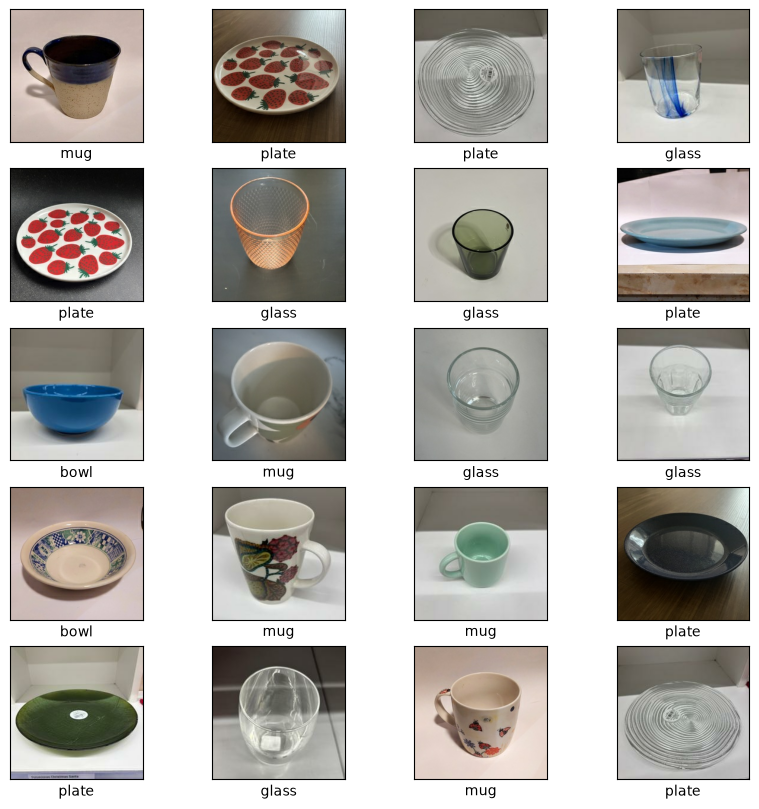

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))

class_names = train_dataset.class_names

for images, labels in train_dataset.take(1):
    for i in range(20):
        plt.subplot(5, 4, i + 1)
        plt.xticks([])
        plt.yticks([])
        plt.grid(False)

        plt.imshow(images[i].numpy().astype("uint8"))
        plt.xlabel(class_names[labels[i]])

plt.show()

In [4]:
conv_base = keras.applications.vgg16.VGG16(
    weights="imagenet",
    include_top=False)

conv_base.trainable = False

conv_base.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, None, None, 3)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, None, None, 64) │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, None, None, 64) │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, None, None, 64) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, None, None,     │        73,856 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, None, None,     │       147,584 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, None, None,     │             0 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, None, None,     │       295,168 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, None, None,     │       590,080 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, None, None,     │       590,080 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, None, None,     │             0 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, None, None,     │     1,180,160 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, None, None,     │             0 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │             

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 14,714,688 (56.13 MB)

In [5]:
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.2)
    ]
)

inputs = keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = keras.applications.vgg16.preprocess_input(x)
x = conv_base(x)
x = layers.Flatten()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(4, activation="softmax")(x)

model = keras.Model(inputs, outputs)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential          │ (None, 224, 224,  │          0 │ input_layer_1[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ sequential[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ sequential[0][0]  │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ sequential[0][0]  │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vgg16 (Functional)  │ (None, 7, 7, 512) │ 14,714,688 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 25088)     │          0 │ vgg16[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │  6,422,784 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 4)         │      1,028 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 21,138,500 (80.64 MB)

 Trainable params: 6,423,812 (24.50 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [6]:
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy",metrics=["accuracy"])

In [7]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="feature_extraction_with_data_augmentation.keras",
        save_best_only=True,
        monitor="val_loss")
]

t0 = time.time()

history = model.fit(
    train_dataset,
    epochs=20,
    validation_data=validation_dataset,
    callbacks=callbacks)

train_time = time.time() - t0
print(f"Training time: {train_time:.1f} s")

Epoch 1/20


C:\Users\miner\anaconda3\envs\keras\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


10/10 ━━━━━━━━━━━━━━━━━━━━ 88s 9s/step - accuracy: 0.5270 - loss: 16.3618 - val_accuracy: 0.8387 - val_loss: 1.8432
Epoch 2/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 95s 10s/step - accuracy: 0.8209 - loss: 4.8894 - val_accuracy: 0.8710 - val_loss: 2.2206
Epoch 3/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 116s 12s/step - accuracy: 0.8378 - loss: 2.3166 - val_accuracy: 0.9462 - val_loss: 1.2151
Epoch 4/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 112s 11s/step - accuracy: 0.8851 - loss: 2.1486 - val_accuracy: 0.9462 - val_loss: 0.5137
Epoch 5/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 104s 10s/step - accuracy: 0.9459 - loss: 0.5920 - val_accuracy: 0.9462 - val_loss: 0.7213
Epoch 6/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 113s 12s/step - accuracy: 0.9662 - loss: 0.2649 - val_accuracy: 0.9140 - val_loss: 1.2276
Epoch 7/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 102s 10s/step - accuracy: 0.9662 - loss: 0.3613 - val_accuracy: 0.9355 - val_loss: 0.7117
Epoch 8/20
10/10 ━━━━━━━━━━━━━━━━━━━━ 169s 14s/step - accuracy: 0.9797 - loss: 0.1941 - val_accuracy: 0.9462 - val_lo

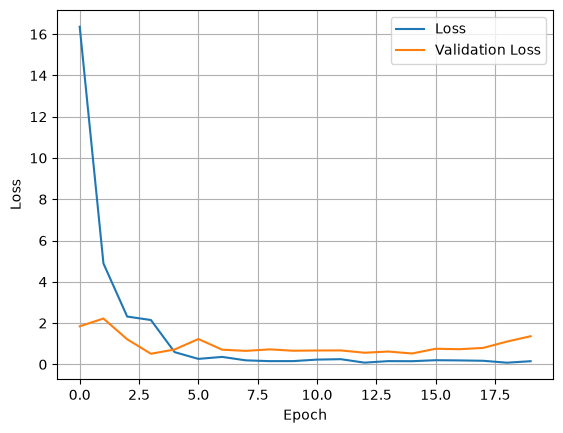

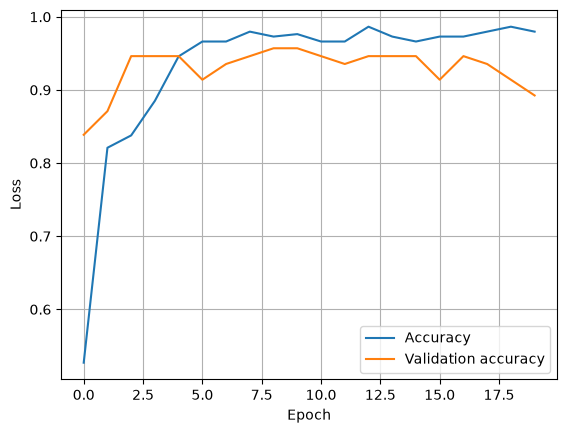

In [8]:
plt.plot(history.history["loss"], label="Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid()
plt.show()

plt.plot(history.history["accuracy"], label="Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid()
plt.show()

In [9]:
test_model = keras.models.load_model("feature_extraction_with_data_augmentation.keras")
test_loss, test_acc = test_model.evaluate(test_dataset)

print(f"Test accuracy: {test_acc:.3f}")
print(f"Test loss: {test_loss:.3f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 28s 9s/step - accuracy: 0.9263 - loss: 1.9880
Test accuracy: 0.926
Test loss: 1.988


In [10]:
conv_base.trainable = True
for layer in conv_base.layers[:-4]:
    layer.trainable = False
    
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])


In [11]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="fine_tuning.keras",
        save_best_only=True,
        monitor="val_loss")
]

t0 = time.time()

history = model.fit(
    train_dataset,
    epochs=30,
    validation_data=validation_dataset,
    callbacks=callbacks)

train_time = time.time() - t0
print(f"Training time: {train_time:.1f} s")

Epoch 1/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 137s 14s/step - accuracy: 0.9764 - loss: 0.1892 - val_accuracy: 0.9140 - val_loss: 1.3775
Epoch 2/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 140s 14s/step - accuracy: 0.9831 - loss: 0.1824 - val_accuracy: 0.9247 - val_loss: 1.4275
Epoch 3/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 119s 12s/step - accuracy: 0.9797 - loss: 0.1002 - val_accuracy: 0.9247 - val_loss: 1.2210
Epoch 4/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 124s 13s/step - accuracy: 0.9696 - loss: 0.2175 - val_accuracy: 0.9032 - val_loss: 1.1397
Epoch 5/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 130s 12s/step - accuracy: 0.9730 - loss: 0.2737 - val_accuracy: 0.8925 - val_loss: 1.2987
Epoch 6/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 110s 11s/step - accuracy: 0.9662 - loss: 0.3445 - val_accuracy: 0.9032 - val_loss: 1.2534
Epoch 7/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 118s 12s/step - accuracy: 0.9764 - loss: 0.1730 - val_accuracy: 0.9140 - val_loss: 1.1441
Epoch 8/30
10/10 ━━━━━━━━━━━━━━━━━━━━ 136s 14s/step - accuracy: 0.9932 - loss: 0.0194 - val_accuracy: 0.

In [12]:
test_model = keras.models.load_model("fine_tuning.keras")
test_loss, test_acc = test_model.evaluate(test_dataset)

print(f"Test accuracy: {test_acc:.3f}")
print(f"Test loss: {test_loss:.3f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 22s 7s/step - accuracy: 0.9263 - loss: 1.4520
Test accuracy: 0.926
Test loss: 1.452


In [13]:
y_true = np.concatenate([y for x, y in test_dataset], axis=0)

probs = test_model.predict(test_dataset)
y_pred = np.argmax(probs, axis=1)

print(classification_report(y_true, y_pred, target_names=class_names))

3/3 ━━━━━━━━━━━━━━━━━━━━ 27s 8s/step
              precision    recall  f1-score   support

        bowl       0.90      1.00      0.95        26
       glass       0.88      0.96      0.92        24
         mug       0.94      0.81      0.87        21
       plate       1.00      0.92      0.96        24

    accuracy                           0.93        95
   macro avg       0.93      0.92      0.92        95
weighted avg       0.93      0.93      0.93        95



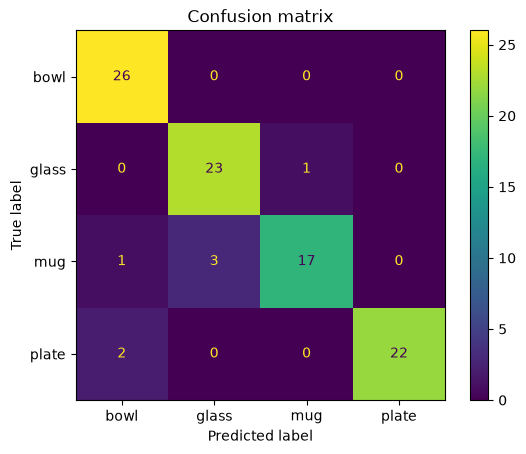

In [14]:
cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot()
plt.title("Confusion matrix")
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 8s 8s/step


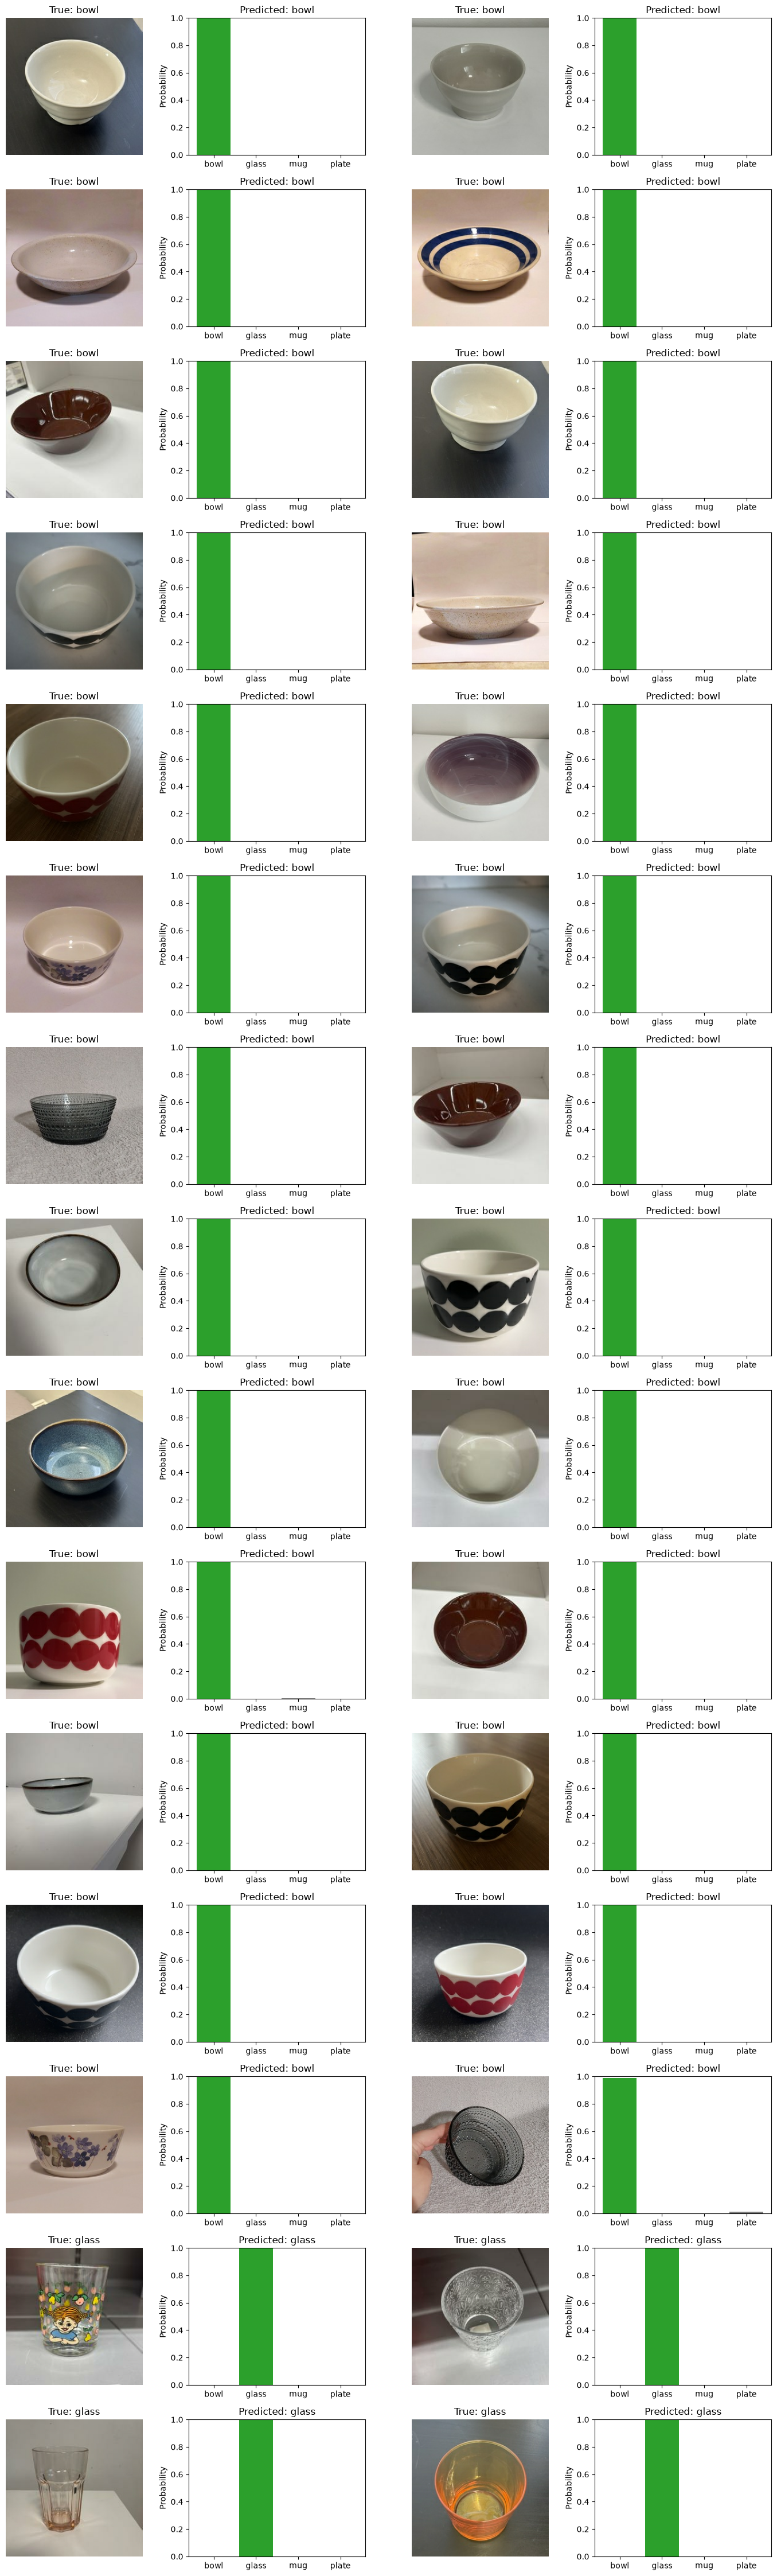

In [15]:
x, y = next(iter(test_dataset)) 
probs = test_model.predict(x)

start = 0
images_n = 30
rows = images_n // 2

plt.figure(figsize=(14, 3 * rows))

for k in range(images_n):
    i = start + k
    true_label = int(y[i])
    pred_label = int(np.argmax(probs[i]))
    correct = true_label == pred_label

    plt.subplot(rows, 4, 2 * k + 1)
    plt.imshow(x[i].numpy().astype("uint8"))
    plt.axis("off")
    plt.title(f"True: {class_names[true_label]}")

    plt.subplot(rows, 4, 2 * k + 2)
    colors = ["tab:gray"] * len(class_names)
    colors[pred_label] = "tab:green" if correct else "tab:red"
    plt.bar(class_names, probs[i], color=colors)
    plt.ylim(0, 1)
    plt.ylabel("Probability")
    plt.title(f"Predicted: {class_names[pred_label]}")

plt.tight_layout()
plt.show()